In [4]:
pip install scikit-learn matplotlib

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


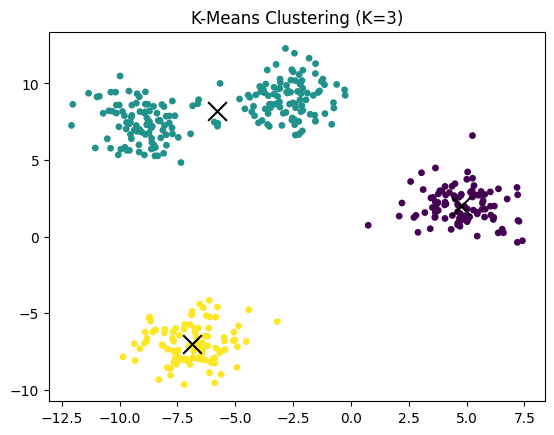

Centers: [[ 4.76854828  2.01807919]
 [-5.80271369  8.22153737]
 [-6.88472071 -7.00475906]]
Inertia: 3218.6613624115


In [5]:

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Generate 400 points from 4 clusters
X, y_true = make_blobs(
    n_samples=400,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

# Fit K-Means
model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

y_pred = model.fit_predict(X) #本质就是 反复执行assignment和update直到收敛

#同时，ypred保存了400个samples的聚类结果，y_true是原始的标签

#额外解释一下 inertia就是平均的平方误差
# Visualize
plt.scatter(X[:, 0], X[:, 1], c=y_pred, s=15)
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    marker="x",
    s=180,
    c="black"
)
plt.title("K-Means Clustering (K=3)")
plt.show()

print("Centers:", model.cluster_centers_)
print("Inertia:", model.inertia_)


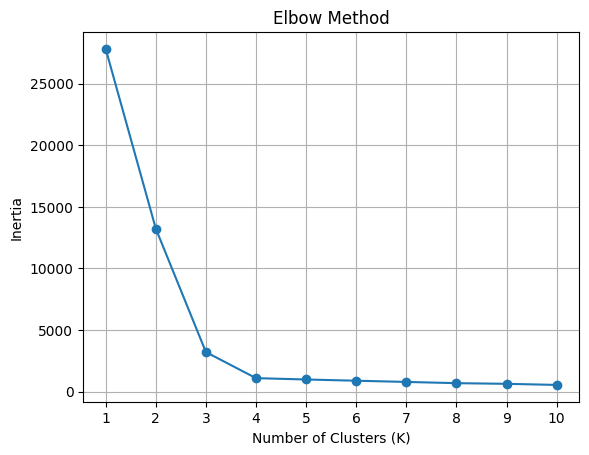

In [6]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [ ]:

import numpy as np

X = np.array([1., 8., 10., 3.])
centers = np.array([1., 9.])

# Cat = 0, Dog = 1, Unknown = -1
labels = np.array([0, 1, 1, -1])

# Step 1: Ordinary Assignment
distances = np.abs(X[:, None] - centers[None, :])
assignments = np.argmin(distances, axis=1)

# Step 2: Apply Known Labels
known = labels != -1
assignments[known] = labels[known]

# Step 3: Update Centers
new_centers = np.array([
    X[assignments == k].mean()
    for k in range(2)
])

print("Assignments:", assignments)
print("New Centers:", new_centers)


Assignments: [0 1 1 0]
New Centers: [2. 9.]


In [22]:
X = np.array([1., 8., 10., 3.])
centers = np.array([1., 9.])
print(X[:,None])
print(centers[None, :])
distance = abs(X[:,None] - centers[None,:])
distance

[[ 1.]
 [ 8.]
 [10.]
 [ 3.]]
[[1. 9.]]


array([[0., 8.],
       [7., 1.],
       [9., 1.],
       [2., 6.]])

In [24]:

import numpy as np

# 8 samples represented by 1D embeddings
X = np.array([1., 2., 3.6, 9., 1.5, 8.5, 14., 15.])

# 0 = Cat, 1 = Dog, -1 = Unlabeled
labels = np.array([0, 0, 1, 1, -1, -1, -1, -1])

# Initial centers: Cat, Dog, Novel category
centers = np.array([1.5, 6.3, 14.])


In [ ]:

# 1. Calculate distances
distances = abs(X[:,None] - centers[None,:])

# 2. Assign each point to its nearest center
assignments = np.argmin(distances, axis=1)

# 3. Create a boolean mask for labeled points
known = labels != -1

# 4. Enforce ground-truth labels
assignments[known] = labels[known]

print("Distances:", distances)
print("Known:", known)
print("Assignments:", assignments)




Distances: [[ 0.5  5.3 13. ]
 [ 0.5  4.3 12. ]
 [ 2.1  2.7 10.4]
 [ 7.5  2.7  5. ]
 [ 0.   4.8 12.5]
 [ 7.   2.2  5.5]
 [12.5  7.7  0. ]
 [13.5  8.7  1. ]]
Known: [ True  True  True  True False False False False]
Assignments: [0 0 1 1 0 1 2 2]


In [51]:

new_centers = np.zeros(3)

for k in range(3):
    # TODO 1: Select samples assigned to cluster k
    selected = X[assignments == k]
    # TODO 2: Calculate their mean
    total = selected.mean()
    # TODO 3: Store the result in new_centers[k]
    new_centers[k] = total

print("Old centers:", centers)
print("New centers:", new_centers)


Old centers: [ 1.5  6.3 14. ]
New centers: [ 1.5         7.03333333 14.5       ]


In [ ]:

centers = np.array([1.5, 4.5, 9.5])

for iteration in range(20):

    # Step 1: Assignment
    distances = np.abs(X[:, None] - centers[None, :])
    assignments = np.argmin(distances, axis=1)

    # Step 2: Label constraints
    known = labels != -1
    assignments[known] = labels[known]  # TODO 2

    # Step 3: Update
    new_centers = np.zeros_like(centers)

    for k in range(len(centers)):
        selected = X[assignments == k]  # TODO 3
        new_centers[k] = selected.mean()

    print(f"Iteration {iteration}")
    print("Assignments:", assignments)
    print("Old Centers:", centers)
    print("New Centers:", new_centers)
    # Step 4: Check convergence
    if np.allclose(new_centers, centers):
        print("Converged!")
        break

    # Step 5: Update centers for next iteration
    centers = new_centers  # TODO 4


Iteration 0
Assignments: [0 0 1 1 0 2 2 2]
Old Centers: [1.5 4.5 9.5]
New Centers: [ 1.5  6.3 12.5]
Iteration 1
Assignments: [0 0 1 1 0 1 2 2]
Old Centers: [ 1.5  6.3 12.5]
New Centers: [ 1.5         7.03333333 14.5       ]
Iteration 2
Assignments: [0 0 1 1 0 1 2 2]
Old Centers: [ 1.5         7.03333333 14.5       ]
New Centers: [ 1.5         7.03333333 14.5       ]
Converged!


In [56]:
centers = np.array([1.5, 6.3, 14.])

# All samples are unlabeled
labels = np.full(8, -1, dtype=int)

In [59]:
centers = np.array([1.5, 6.3, 14.])


for iteration in range(20):

    # Step 1: Assignment
    distances = np.abs(X[:, None] - centers[None, :])
    assignments = np.argmin(distances, axis=1)

    # Step 2: Label constraints
    known = labels != -1
    assignments[known] = labels[known]  # TODO 2

    # Step 3: Update
    new_centers = np.zeros_like(centers)

    for k in range(len(centers)):
        selected = X[assignments == k]  # TODO 3
        new_centers[k] = selected.mean()

    print(f"Iteration {iteration}")
    print("Assignments:", assignments)
    print("Old Centers:", centers)
    print("New Centers:", new_centers)
    # Step 4: Check convergence
    if np.allclose(new_centers, centers):
        print("Converged!")
        break

    # Step 5: Update centers for next iteration
    centers = new_centers  # TODO 4


Iteration 0
Assignments: [0 0 0 1 0 1 2 2]
Old Centers: [ 1.5  6.3 14. ]
New Centers: [ 2.025  8.75  14.5  ]
Iteration 1
Assignments: [0 0 0 1 0 1 2 2]
Old Centers: [ 2.025  8.75  14.5  ]
New Centers: [ 2.025  8.75  14.5  ]
Converged!
